# ResNet-18 compression baseline

Manuscript section 3.5.2: train a ResNet-18 baseline on the harmonized images, then measure how its
accuracy drops under social-media compression (clean vs JPEG 90/70/50/30, WebP, downscaling,
repeated recompression). ΔA = A_clean − A_compressed is the baseline the multi-signal framework
is compared against.

Before starting: **Runtime > Change runtime type > T4 GPU**, and run notebook 01 through step 8 once
so the prepared data is saved on Google Drive.

## 1. Get the code and check the GPU

In [1]:
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd repo
!pip install -q -e ".[train,dev]"
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (training will be very slow)")

fatal: destination path 'repo' already exists and is not an empty directory.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done
GPU: NVIDIA L4


## 2. Restore the prepared data from Google Drive

In [2]:
from google.colab import drive
import os
drive.mount("/content/drive")
ZIP = "/content/drive/MyDrive/thesis-data/harmonized.zip"
if not os.path.exists(ZIP):
    raise FileNotFoundError(f"{ZIP} not found: run notebook 01 through step 8 first, it saves the prepared data there")
!unzip -qo $ZIP -d .
!wc -l data/harmonized/train.csv data/harmonized/val.csv data/harmonized/test.csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  13962 data/harmonized/train.csv
   2993 data/harmonized/val.csv
   2993 data/harmonized/test.csv
  19948 total


## 3. Train ResNet-18
Up to 50 epochs with early stopping (stops after 5 epochs without validation improvement).
Each epoch prints training loss, validation loss and validation accuracy. Checkpoints are
written to Google Drive as well, so a disconnect doesn't lose the model.

In [3]:
!mkdir -p /content/drive/MyDrive/thesis-data/models && rm -rf outputs/models && ln -s /content/drive/MyDrive/thesis-data/models outputs/models
!python scripts/train.py --arch resnet18

training resnet18 on cuda: 13961 train / 2992 val images
epoch 1: train_loss=0.3699 val_loss=0.3460 val_acc=0.8563
epoch 2: train_loss=0.2591 val_loss=0.2392 val_acc=0.9061
epoch 3: train_loss=0.2157 val_loss=0.2962 val_acc=0.8767
epoch 4: train_loss=0.1831 val_loss=0.3199 val_acc=0.8930
epoch 5: train_loss=0.1604 val_loss=0.2823 val_acc=0.8961
epoch 6: train_loss=0.1378 val_loss=0.3754 val_acc=0.8864
epoch 7: train_loss=0.1212 val_loss=0.2707 val_acc=0.9078
early stop: no val improvement for 5 epochs
saved outputs/models/resnet18/best.pt, temperature=1.232


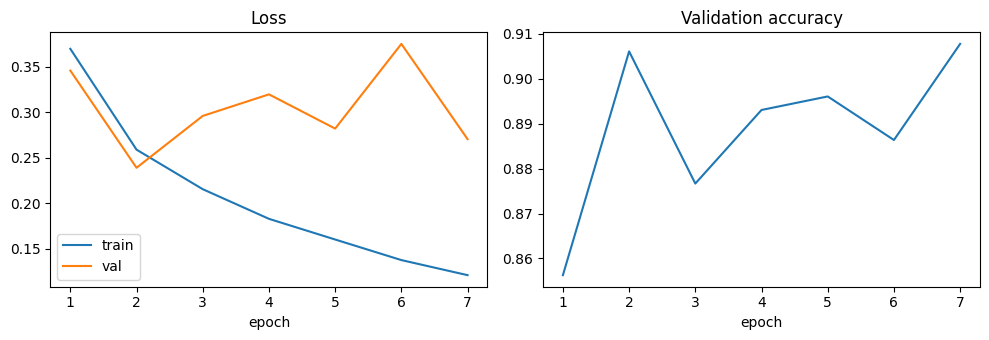

In [4]:
import json, matplotlib.pyplot as plt
h = json.load(open("outputs/models/resnet18/history.json"))
ep = [r["epoch"] for r in h]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ep, [r["train_loss"] for r in h], label="train"); axes[0].plot(ep, [r["val_loss"] for r in h], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(ep, [r["val_acc"] for r in h]); axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch")
plt.tight_layout()

## 4. Compression stress test
Evaluates the best checkpoint on the test split under every transformation in the config.
Results go to `outputs/stress_test/resnet18/results.csv`.

In [5]:
!mkdir -p /content/drive/MyDrive/thesis-data/stress_test && rm -rf outputs/stress_test && ln -s /content/drive/MyDrive/thesis-data/stress_test outputs/stress_test
!python scripts/stress_test.py --arch resnet18

         clean: acc=0.9141 f1=0.9149 fpr=0.0974 ece=0.0209
      jpeg_q90: acc=0.9071 f1=0.9064 fpr=0.0874 ece=0.0233
      jpeg_q70: acc=0.8820 f1=0.8748 fpr=0.0620 ece=0.0192
      jpeg_q50: acc=0.8483 f1=0.8292 fpr=0.0420 ece=0.0416
      jpeg_q30: acc=0.7888 f1=0.7393 fpr=0.0233 ece=0.1019
      webp_q80: acc=0.8961 f1=0.8928 fpr=0.0754 ece=0.0153
    resize_0.5: acc=0.8185 f1=0.7870 fpr=0.0354 ece=0.0700
   resize_0.25: acc=0.6487 f1=0.4695 fpr=0.0153 ece=0.2673
 recompress_x3: acc=0.8854 f1=0.8787 fpr=0.0614 ece=0.0185
results: outputs/stress_test/resnet18/results.csv


,condition,accuracy,precision,recall,f1,fpr,ece,delta_a
0,clean,0.9141,0.9045,0.9257,0.9149,0.0974,0.0209,0.0000
1,jpeg_q90,0.9071,0.9113,0.9015,0.9064,0.0874,0.0233,0.0070
2,jpeg_q70,0.8820,0.9299,0.8259,0.8748,0.0620,0.0192,0.0321
3,jpeg_q50,0.8483,0.9459,0.7381,0.8292,0.0420,0.0416,0.0658
4,jpeg_q30,0.7888,0.9624,0.6001,0.7393,0.0233,0.1019,0.1253
5,webp_q80,0.8961,0.9197,0.8674,0.8928,0.0754,0.0153,0.0180
6,resize_0.5,0.8185,0.9498,0.6718,0.7870,0.0354,0.0700,0.0956
7,resize_0.25,0.6487,0.9529,0.3115,0.4695,0.0153,0.2673,0.2654
8,recompress_x3,0.8854,0.9310,0.8319,0.8787,0.0614,0.0185,0.0287


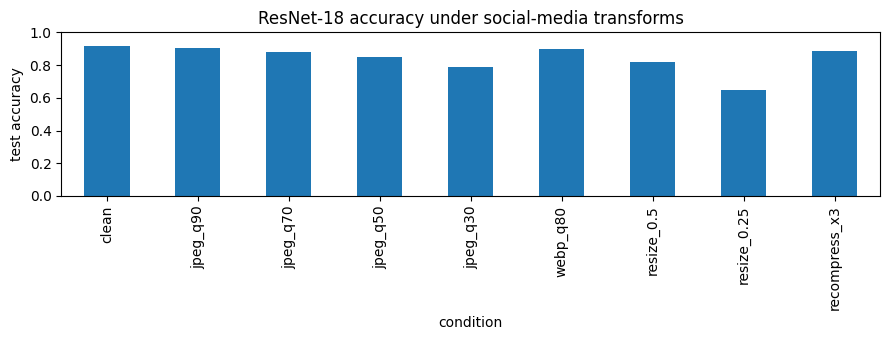

In [6]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("outputs/stress_test/resnet18/results.csv")
display(df.round(4))
ax = df.plot.bar(x="condition", y="accuracy", legend=False, figsize=(9, 3.5), ylim=(0, 1))
ax.set_ylabel("test accuracy"); ax.set_title("ResNet-18 accuracy under social-media transforms")
plt.tight_layout()

## 5. ResNet-50 and EfficientNet-B0
The two main backbones from the manuscript, trained and stress-tested exactly like ResNet-18.
Each takes roughly 10-20 minutes on an L4. Results go to the same Drive folders, one subfolder per model.

In [7]:
# Link outputs to Drive (safe to re-run; needed if you skipped sections 3-4 in this session)
for d in ["models", "stress_test"]:
    !mkdir -p /content/drive/MyDrive/thesis-data/$d && rm -rf outputs/$d && ln -s /content/drive/MyDrive/thesis-data/$d outputs/$d

In [8]:
!python scripts/train.py --arch resnet50
!python scripts/stress_test.py --arch resnet50

training resnet50 on cuda: 13961 train / 2992 val images
epoch 1: train_loss=0.3295 val_loss=0.2324 val_acc=0.8994
epoch 2: train_loss=0.1995 val_loss=0.2145 val_acc=0.9121
epoch 3: train_loss=0.1493 val_loss=0.2117 val_acc=0.9291
epoch 4: train_loss=0.1212 val_loss=0.2344 val_acc=0.9128
epoch 5: train_loss=0.0968 val_loss=0.2404 val_acc=0.9198
epoch 6: train_loss=0.0857 val_loss=0.2662 val_acc=0.9161
epoch 7: train_loss=0.0747 val_loss=0.2315 val_acc=0.9325
epoch 8: train_loss=0.0676 val_loss=0.2312 val_acc=0.9308
early stop: no val improvement for 5 epochs
saved outputs/models/resnet50/best.pt, temperature=1.575
         clean: acc=0.9332 f1=0.9321 fpr=0.0527 ece=0.0156
      jpeg_q90: acc=0.9021 f1=0.9001 fpr=0.0801 ece=0.0233
      jpeg_q70: acc=0.8463 f1=0.8320 fpr=0.0707 ece=0.0497
      jpeg_q50: acc=0.7934 f1=0.7666 fpr=0.0934 ece=0.0815
      jpeg_q30: acc=0.7457 f1=0.7003 fpr=0.1047 ece=0.1197
      webp_q80: acc=0.8934 f1=0.8872 fpr=0.0534 ece=0.0149
    resize_0.5: acc=0.84

In [9]:
!python scripts/train.py --arch efficientnet_b0
!python scripts/stress_test.py --arch efficientnet_b0

training efficientnet_b0 on cuda: 13961 train / 2992 val images
epoch 1: train_loss=0.3624 val_loss=0.2288 val_acc=0.9068
epoch 2: train_loss=0.2176 val_loss=0.2023 val_acc=0.9168
epoch 3: train_loss=0.1667 val_loss=0.1868 val_acc=0.9271
epoch 4: train_loss=0.1415 val_loss=0.1890 val_acc=0.9281
epoch 5: train_loss=0.1109 val_loss=0.2050 val_acc=0.9318
epoch 6: train_loss=0.0931 val_loss=0.2144 val_acc=0.9268
epoch 7: train_loss=0.0735 val_loss=0.2173 val_acc=0.9311
epoch 8: train_loss=0.0642 val_loss=0.2181 val_acc=0.9358
early stop: no val improvement for 5 epochs
saved outputs/models/efficientnet_b0/best.pt, temperature=1.218
         clean: acc=0.9372 f1=0.9376 fpr=0.0720 ece=0.0173
      jpeg_q90: acc=0.9188 f1=0.9190 fpr=0.0854 ece=0.0120
      jpeg_q70: acc=0.8559 f1=0.8458 fpr=0.0801 ece=0.0360
      jpeg_q50: acc=0.8239 f1=0.8043 fpr=0.0781 ece=0.0657
      jpeg_q30: acc=0.7918 f1=0.7618 fpr=0.0841 ece=0.0867
      webp_q80: acc=0.8954 f1=0.8901 fpr=0.0587 ece=0.0161
    resize

## 6. Compare all three
Test accuracy and ΔA (A_clean − A_condition) per condition for each backbone.

arch,efficientnet_b0,resnet18,resnet50
condition,,,
clean,0.9372,0.9141,0.9332
jpeg_q90,0.9188,0.9071,0.9021
jpeg_q70,0.8559,0.8820,0.8463
jpeg_q50,0.8239,0.8483,0.7934
jpeg_q30,0.7918,0.7888,0.7457
webp_q80,0.8954,0.8961,0.8934
resize_0.5,0.8529,0.8185,0.8466
resize_0.25,0.6491,0.6487,0.7751
recompress_x3,0.8670,0.8854,0.8529


arch,efficientnet_b0,resnet18,resnet50
condition,,,
clean,0.0000,0.0000,0.0000
jpeg_q90,0.0184,0.0070,0.0311
jpeg_q70,0.0812,0.0321,0.0869
jpeg_q50,0.1133,0.0658,0.1397
jpeg_q30,0.1454,0.1253,0.1875
webp_q80,0.0418,0.0180,0.0398
resize_0.5,0.0842,0.0956,0.0866
resize_0.25,0.2881,0.2654,0.1581
recompress_x3,0.0702,0.0287,0.0802


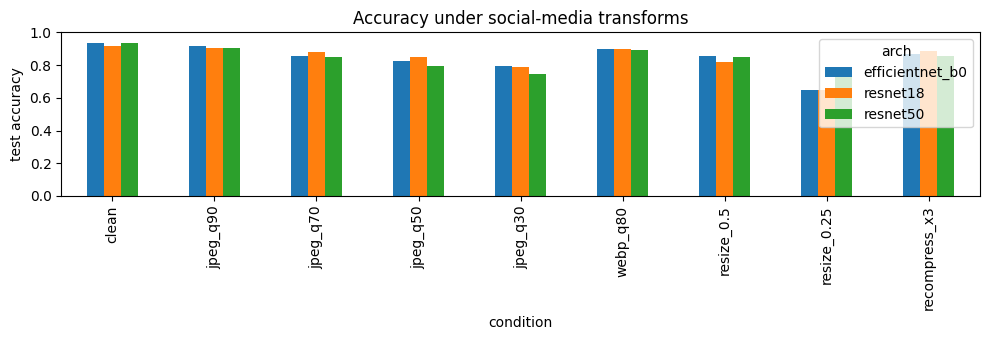

In [10]:
import pandas as pd, matplotlib.pyplot as plt
archs = ["resnet18", "resnet50", "efficientnet_b0"]
df = pd.concat([pd.read_csv(f"outputs/stress_test/{a}/results.csv").assign(arch=a) for a in archs])
display(df.pivot(index="condition", columns="arch", values="accuracy").loc[df.condition.unique()].round(4))
display(df.pivot(index="condition", columns="arch", values="delta_a").loc[df.condition.unique()].round(4))
ax = df.pivot(index="condition", columns="arch", values="accuracy").loc[df.condition.unique()].plot.bar(figsize=(10, 3.5), ylim=(0, 1))
ax.set_ylabel("test accuracy"); ax.set_title("Accuracy under social-media transforms")
plt.tight_layout()